In [ ]:
!pip install -q geopandas shapely folium mapclassify

In [ ]:
import os
import warnings
import json

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import folium

from shapely.geometry import Point, LineString, MultiLineString
from IPython.display import display

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")
print("GeoPandas version:", gpd.__version__)

Libraries imported successfully!
GeoPandas version: 1.2.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

ROAD_PATH = BASE_PATH + "/datasets/raw/roads"

PROCESSED_PATH = BASE_PATH + "/datasets/processed"
GIS_OUTPUT_PATH = PROCESSED_PATH + "/gis"

REPORT_PATH = BASE_PATH + "/reports/gis_processing"

os.makedirs(GIS_OUTPUT_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Road data folder exists:", os.path.exists(ROAD_PATH))
print("GIS output folder:", GIS_OUTPUT_PATH)

Road data folder exists: True
GIS output folder: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis


In [ ]:
geojson_files = [
    "flyovers.geojson",
    "link_roads.geojson",
    "major_roads.geojson",
    "national_highways.geojson",
    "parking_north.geojson",
    "parking_southeast.geojson",
    "parking_southwest.geojson",
    "poi.geojson",
    "state_highways.geojson",
    "traffic_junctions.geojson",
    "traffic50.geojson"
]

for file in geojson_files:
    path = os.path.join(ROAD_PATH, file)

    if os.path.exists(path):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

FOUND: flyovers.geojson
FOUND: link_roads.geojson
FOUND: major_roads.geojson
FOUND: national_highways.geojson
FOUND: parking_north.geojson
FOUND: parking_southeast.geojson
FOUND: parking_southwest.geojson
FOUND: poi.geojson
FOUND: state_highways.geojson
FOUND: traffic_junctions.geojson
FOUND: traffic50.geojson


In [ ]:
gis_data = {}

for file in geojson_files:

    path = os.path.join(ROAD_PATH, file)

    if os.path.exists(path):

        layer_name = file.replace(".geojson", "")

        try:
            gdf = gpd.read_file(path)
            gis_data[layer_name] = gdf

            print(
                layer_name,
                "| Rows:", len(gdf),
                "| CRS:", gdf.crs,
                "| Geometry:", gdf.geom_type.value_counts().to_dict()
            )

        except Exception as e:
            print("Error loading", file, ":", e)

    else:
        print("Skipped missing file:", file)

flyovers | Rows: 42 | CRS: EPSG:4326 | Geometry: {'LineString': 42}
link_roads | Rows: 1000 | CRS: EPSG:4326 | Geometry: {'LineString': 1000}
major_roads | Rows: 1000 | CRS: EPSG:4326 | Geometry: {'LineString': 1000}
national_highways | Rows: 456 | CRS: EPSG:4326 | Geometry: {'LineString': 456}
parking_north | Rows: 21 | CRS: EPSG:4326 | Geometry: {'Polygon': 21}
parking_southeast | Rows: 74 | CRS: EPSG:4326 | Geometry: {'Polygon': 74}
parking_southwest | Rows: 39 | CRS: EPSG:4326 | Geometry: {'Polygon': 39}
poi | Rows: 1000 | CRS: EPSG:4326 | Geometry: {'Point': 1000}
state_highways | Rows: 76 | CRS: EPSG:4326 | Geometry: {'LineString': 76}
traffic_junctions | Rows: 50 | CRS: EPSG:4326 | Geometry: {'Point': 50}
traffic50 | Rows: 50 | CRS: EPSG:4326 | Geometry: {'Point': 50}


In [ ]:
print("Total layers loaded:", len(gis_data))

for name, gdf in gis_data.items():
    print(name, ":", gdf.shape)

Total layers loaded: 11
flyovers : (42, 11)
link_roads : (1000, 11)
major_roads : (1000, 11)
national_highways : (456, 11)
parking_north : (21, 15)
parking_southeast : (74, 15)
parking_southwest : (39, 15)
poi : (1000, 3)
state_highways : (76, 11)
traffic_junctions : (50, 12)
traffic50 : (50, 12)


In [ ]:
for name, gdf in gis_data.items():

    print("\n------------------------------")
    print("LAYER:", name)
    print("------------------------------")

    print("Columns:", gdf.columns.tolist())

    display(gdf.head(3))


------------------------------
LAYER: flyovers
------------------------------
Columns: ['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,Flyover,None,Flyover,NaN,NaN,0,1224.178247,None,551.868985,"LINESTRING (85.8245 20.24076, 85.82429 20.2404..."
1,2,Flyover,None,Flyover,NaN,NaN,0,1397.852030,None,1397.697084,"LINESTRING (85.74657 20.23541, 85.74811 20.236..."
2,3,Flyover,None,Flyover,NaN,NaN,0,1397.852030,None,0.154946,"LINESTRING (85.75829 20.24145, 85.75829 20.24145)"



------------------------------
LAYER: link_roads
------------------------------
Columns: ['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,None,,Link Road,0,0,0,48.002004,None,48.002004,"LINESTRING (85.70815 20.14945, 85.70812 20.14901)"
1,2,None,,Link Road,0,0,0,199.432903,None,199.432903,"LINESTRING (85.70815 20.14945, 85.70789 20.149..."
2,3,None,,Link Road,0,0,0,39.759587,None,39.759587,"LINESTRING (85.70351 20.14954, 85.70355 20.149..."



------------------------------
LAYER: major_roads
------------------------------
Columns: ['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,Atri Rd,,Major Road,0.0,0.0,0.0,17.280351,None,17.280351,"LINESTRING (85.60327 20.15366, 85.60334 20.1538)"
1,2,Atri Rd,,Major Road,0.0,0.0,0.0,109.837033,None,109.837033,"LINESTRING (85.60334 20.1538, 85.60375 20.1546..."
2,3,Atri Rd,,Major Road,0.0,0.0,0.0,229.941355,None,229.941355,"LINESTRING (85.60376 20.15471, 85.60394 20.155..."


... (12 outputs left out)


------------------------------
LAYER: traffic_junctions
------------------------------
Columns: ['OBJECTID', 'OID_', 'Name', 'FolderPath', 'SymbolID', 'AltMode', 'Base', 'Snippet', 'PopupInfo', 'HasLabel', 'LabelID', 'geometry']


,OBJECTID,OID_,Name,FolderPath,SymbolID,AltMode,Base,Snippet,PopupInfo,HasLabel,LabelID,geometry
0,1,0,CAPITAL HOSPITAL,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.82496 20.26013 0)
1,2,0,AG SQUARE,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.82982 20.26638 0)
2,3,0,PMG SQUARE,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.83312 20.27185 0)



------------------------------
LAYER: traffic50
------------------------------
Columns: ['objectid', 'oid_', 'name', 'folderpath', 'symbolid', 'altmode', 'base', 'snippet', 'popupinfo', 'haslabel', 'labelid', 'geometry']


,objectid,oid_,name,folderpath,symbolid,altmode,base,snippet,popupinfo,haslabel,labelid,geometry
0,1,0,CAPITAL HOSPITAL,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.82496 20.26013 0)
1,2,0,AG SQUARE,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.82982 20.26638 0)
2,3,0,PMG SQUARE,Document/lat_long_details,0,-1,0,,,-1,0,POINT Z (85.83312 20.27185 0)


In [ ]:
inventory = []

for name, gdf in gis_data.items():

    inventory.append({
        "layer_name": name,
        "total_features": len(gdf),
        "total_columns": len(gdf.columns),
        "crs": str(gdf.crs),
        "geometry_types": ", ".join(
            gdf.geom_type.dropna().unique().tolist()
        ),
        "missing_geometry": gdf.geometry.isna().sum(),
        "invalid_geometry": (
            (~gdf.geometry.is_valid) &
            gdf.geometry.notna()
        ).sum()
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

inventory_df.to_csv(
    REPORT_PATH + "/gis_layer_inventory.csv",
    index=False
)

,layer_name,total_features,total_columns,crs,geometry_types,missing_geometry,invalid_geometry
0,flyovers,42,11,EPSG:4326,LineString,0,0
1,link_roads,1000,11,EPSG:4326,LineString,0,0
2,major_roads,1000,11,EPSG:4326,LineString,0,0
3,national_highways,456,11,EPSG:4326,LineString,0,0
4,parking_north,21,15,EPSG:4326,Polygon,0,0
5,parking_southeast,74,15,EPSG:4326,Polygon,0,0
6,parking_southwest,39,15,EPSG:4326,Polygon,0,0
7,poi,1000,3,EPSG:4326,Point,0,0
8,state_highways,76,11,EPSG:4326,LineString,0,0
9,traffic_junctions,50,12,EPSG:4326,Point,0,0


In [ ]:
def clean_gis_layer(gdf):

    gdf = gdf.copy()

    # Remove missing geometries
    gdf = gdf[gdf.geometry.notna()].copy()

    # Remove empty geometries
    gdf = gdf[~gdf.geometry.is_empty].copy()

    # Repair invalid geometries
    invalid_before = (~gdf.geometry.is_valid).sum()

    if invalid_before > 0:
        try:
            gdf.geometry = gdf.geometry.make_valid()
        except Exception:
            gdf.geometry = gdf.geometry.buffer(0)

    # Remove geometries that became empty
    gdf = gdf[
        gdf.geometry.notna() &
        (~gdf.geometry.is_empty)
    ].copy()

    # Remove duplicate records
    gdf = gdf.drop_duplicates().copy()

    return gdf

In [ ]:
cleaned_data = {}

for name, gdf in gis_data.items():

    if gdf.crs is None:
        print("CRS missing - needs inspection:", name)
        continue

    cleaned = clean_gis_layer(gdf)

    # Standardize coordinate system
    cleaned = cleaned.to_crs(epsg=4326)

    cleaned_data[name] = cleaned

    print(
        name,
        "| Original:", len(gdf),
        "| Cleaned:", len(cleaned),
        "| CRS:", cleaned.crs
    )

flyovers | Original: 42 | Cleaned: 42 | CRS: EPSG:4326
link_roads | Original: 1000 | Cleaned: 1000 | CRS: EPSG:4326
major_roads | Original: 1000 | Cleaned: 1000 | CRS: EPSG:4326
national_highways | Original: 456 | Cleaned: 456 | CRS: EPSG:4326
parking_north | Original: 21 | Cleaned: 21 | CRS: EPSG:4326
parking_southeast | Original: 74 | Cleaned: 74 | CRS: EPSG:4326
parking_southwest | Original: 39 | Cleaned: 39 | CRS: EPSG:4326
poi | Original: 1000 | Cleaned: 1000 | CRS: EPSG:4326
state_highways | Original: 76 | Cleaned: 76 | CRS: EPSG:4326
traffic_junctions | Original: 50 | Cleaned: 50 | CRS: EPSG:4326
traffic50 | Original: 50 | Cleaned: 50 | CRS: EPSG:4326


In [ ]:
quality_records = []

for name, gdf in cleaned_data.items():

    quality_records.append({
        "layer_name": name,
        "total_features": len(gdf),
        "missing_geometry": gdf.geometry.isna().sum(),
        "empty_geometry": gdf.geometry.is_empty.sum(),
        "invalid_geometry": (~gdf.geometry.is_valid).sum(),
        "duplicate_rows": gdf.duplicated().sum(),
        "missing_attributes": gdf.drop(
            columns="geometry"
        ).isna().sum().sum(),
        "crs": str(gdf.crs)
    })

quality_df = pd.DataFrame(quality_records)

display(quality_df)

quality_df.to_csv(
    REPORT_PATH + "/gis_quality_report.csv",
    index=False
)

,layer_name,total_features,missing_geometry,empty_geometry,invalid_geometry,duplicate_rows,missing_attributes,crs
0,flyovers,42,0,0,0,0,165,EPSG:4326
1,link_roads,1000,0,0,0,0,1953,EPSG:4326
2,major_roads,1000,0,0,0,0,1129,EPSG:4326
3,national_highways,456,0,0,0,0,30,EPSG:4326
4,parking_north,21,0,0,0,0,21,EPSG:4326
5,parking_southeast,74,0,0,0,0,76,EPSG:4326
6,parking_southwest,39,0,0,0,0,59,EPSG:4326
7,poi,1000,0,0,0,0,0,EPSG:4326
8,state_highways,76,0,0,0,0,0,EPSG:4326
9,traffic_junctions,50,0,0,0,0,0,EPSG:4326


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


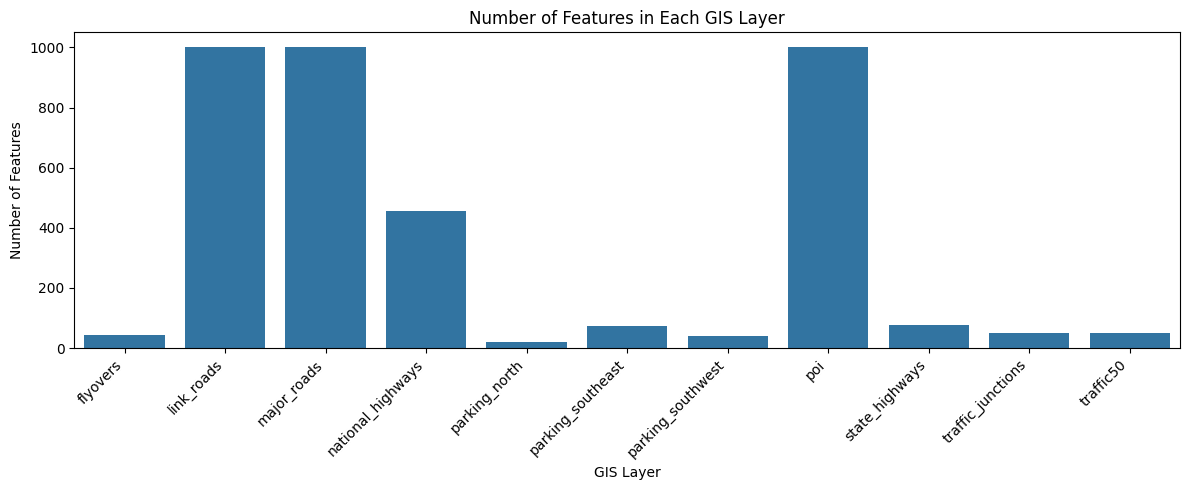

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=inventory_df,
    x="layer_name",
    y="total_features"
)

plt.title("Number of Features in Each GIS Layer")
plt.xlabel("GIS Layer")
plt.ylabel("Number of Features")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/gis_feature_counts.png",
    dpi=300
)

plt.show()

In [ ]:
road_layer_names = [
    "major_roads",
    "link_roads",
    "national_highways",
    "state_highways",
    "flyovers"
]

available_road_layers = [
    name for name in road_layer_names
    if name in cleaned_data
]

print("Available road layers:", available_road_layers)

Available road layers: ['major_roads', 'link_roads', 'national_highways', 'state_highways', 'flyovers']


In [ ]:
road_frames = []

for name in available_road_layers:

    gdf = cleaned_data[name].copy()

    gdf["road_category"] = name

    road_frames.append(gdf)

if road_frames:

    roads_processed = gpd.GeoDataFrame(
        pd.concat(road_frames, ignore_index=True),
        geometry="geometry",
        crs="EPSG:4326"
    )

else:
    raise ValueError("No road layers were loaded successfully.")

print("Combined road dataset:", roads_processed.shape)

display(roads_processed.head())

Combined road dataset: (2574, 12)


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry,road_category
0,1,Atri Rd,,Major Road,0.0,0.0,0.0,17.280351,None,17.280351,"LINESTRING (85.60327 20.15366, 85.60334 20.1538)",major_roads
1,2,Atri Rd,,Major Road,0.0,0.0,0.0,109.837033,None,109.837033,"LINESTRING (85.60334 20.1538, 85.60375 20.1546...",major_roads
2,3,Atri Rd,,Major Road,0.0,0.0,0.0,229.941355,None,229.941355,"LINESTRING (85.60376 20.15471, 85.60394 20.155...",major_roads
3,4,None,None,Major Road,NaN,NaN,0.0,17.159145,None,17.159145,"LINESTRING (85.60469 20.1566, 85.60485 20.15662)",major_roads
4,5,Atri Rd,,Major Road,0.0,0.0,0.0,146.384433,None,146.384433,"LINESTRING (85.60469 20.1566, 85.60525 20.1577...",major_roads


In [ ]:
print("Road columns:")
print(roads_processed.columns.tolist())

print("\nRoad category distribution:")

display(
    roads_processed["road_category"].value_counts()
)

Road columns:
['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry', 'road_category']

Road category distribution:


,count
road_category,
major_roads,1000
link_roads,1000
national_highways,456
state_highways,76
flyovers,42


In [ ]:
parking_names = [
    "parking_north",
    "parking_southeast",
    "parking_southwest"
]

parking_frames = []

for name in parking_names:

    if name in cleaned_data:

        gdf = cleaned_data[name].copy()

        gdf["parking_area"] = name

        parking_frames.append(gdf)

if parking_frames:

    parking_processed = gpd.GeoDataFrame(
        pd.concat(parking_frames, ignore_index=True),
        geometry="geometry",
        crs="EPSG:4326"
    )

    print("Parking features:", len(parking_processed))

else:
    parking_processed = None
    print("No parking layers available.")

Parking features: 134


In [ ]:
if "flyovers" in cleaned_data:

    flyovers_processed = cleaned_data["flyovers"].copy()

    print("Flyover features:", len(flyovers_processed))

else:
    flyovers_processed = None

Flyover features: 42


In [ ]:
if "traffic_junctions" in cleaned_data:

    traffic_junctions_processed = (
        cleaned_data["traffic_junctions"].copy()
    )

    print(
        "Traffic junction features:",
        len(traffic_junctions_processed)
    )

else:
    traffic_junctions_processed = None

Traffic junction features: 50


In [ ]:
if "poi" in cleaned_data:

    poi_processed = cleaned_data["poi"].copy()

    print("POI features:", len(poi_processed))

else:
    poi_processed = None

POI features: 1000


In [ ]:
if "traffic50" in cleaned_data:

    traffic50_processed = cleaned_data["traffic50"].copy()

    print(
        "Traffic layer features:",
        len(traffic50_processed)
    )

else:
    traffic50_processed = None

Traffic layer features: 50


In [ ]:
roads_metric = roads_processed.to_crs(epsg=32645)

roads_metric["road_length_km"] = (
    roads_metric.geometry.length / 1000
)

road_length_summary = (
    roads_metric
    .groupby("road_category")["road_length_km"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

road_length_summary.columns = [
    "road_category",
    "number_of_features",
    "total_length_km",
    "average_length_km"
]

display(road_length_summary.round(3))

road_length_summary.to_csv(
    REPORT_PATH + "/road_length_summary.csv",
    index=False
)

,road_category,number_of_features,total_length_km,average_length_km
0,flyovers,42,15.649,0.373
1,link_roads,1000,93.664,0.094
2,major_roads,1000,102.318,0.102
3,national_highways,456,123.170,0.270
4,state_highways,76,9.810,0.129


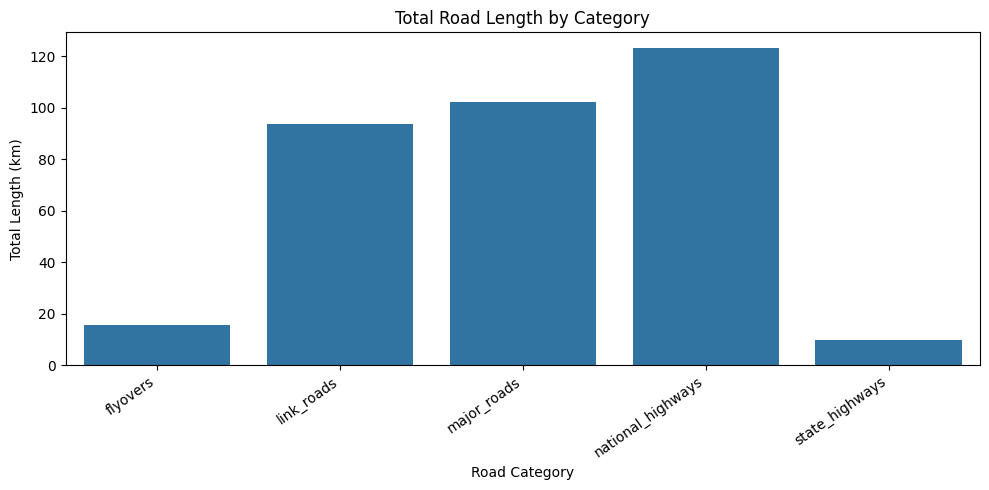

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=road_length_summary,
    x="road_category",
    y="total_length_km"
)

plt.title("Total Road Length by Category")
plt.xlabel("Road Category")
plt.ylabel("Total Length (km)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/road_length_by_category.png",
    dpi=300
)

plt.show()

In [ ]:
roads_output = GIS_OUTPUT_PATH + "/roads_processed.geojson"

roads_processed.to_file(
    roads_output,
    driver="GeoJSON"
)

print("Saved:", roads_output)

Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/roads_processed.geojson


In [ ]:
layers_to_save = {
    "flyovers_processed": flyovers_processed,
    "traffic_junctions_processed": traffic_junctions_processed,
    "parking_processed": parking_processed,
    "poi_processed": poi_processed,
    "traffic50_processed": traffic50_processed
}

for name, gdf in layers_to_save.items():

    if gdf is not None and len(gdf) > 0:

        output_file = GIS_OUTPUT_PATH + "/" + name + ".geojson"

        gdf.to_file(
            output_file,
            driver="GeoJSON"
        )

        print("Saved:", output_file)

    else:
        print("Skipped empty or unavailable layer:", name)

Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/flyovers_processed.geojson
Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/traffic_junctions_processed.geojson
Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/parking_processed.geojson
Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/poi_processed.geojson
Saved: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/gis/traffic50_processed.geojson


In [ ]:
for name, gdf in cleaned_data.items():

    output_file = (
        GIS_OUTPUT_PATH + "/" + name + "_cleaned.geojson"
    )

    gdf.to_file(
        output_file,
        driver="GeoJSON"
    )

    print("Saved:", name)

Saved: flyovers
Saved: link_roads
Saved: major_roads
Saved: national_highways
Saved: parking_north
Saved: parking_southeast
Saved: parking_southwest
Saved: poi
Saved: state_highways
Saved: traffic_junctions
Saved: traffic50


In [ ]:
bounds = roads_processed.total_bounds

min_lon, min_lat, max_lon, max_lat = bounds

center_lat = (min_lat + max_lat) / 2
center_lon = (min_lon + max_lon) / 2

print("Map center:", center_lat, center_lon)
print("Map bounds:", bounds)

Map center: 20.25200247944275 85.74158379715684
Map bounds: [85.59332865 20.14394511 85.88983894 20.36005985]


In [ ]:
gis_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles="OpenStreetMap"
)

In [ ]:
folium.GeoJson(
    roads_processed,
    name="Road Network",
    style_function=lambda feature: {
        "color": "blue",
        "weight": 2,
        "opacity": 0.7
    }
).add_to(gis_map)

In [ ]:
if flyovers_processed is not None and len(flyovers_processed) > 0:

    folium.GeoJson(
        flyovers_processed,
        name="Flyovers",
        style_function=lambda feature: {
            "color": "purple",
            "weight": 3
        }
    ).add_to(gis_map)

In [ ]:
if traffic_junctions_processed is not None:

    folium.GeoJson(
        traffic_junctions_processed,
        name="Traffic Junctions",
        marker=folium.CircleMarker(
            radius=4,
            color="red",
            fill=True,
            fill_opacity=0.8
        )
    ).add_to(gis_map)

In [ ]:
if parking_processed is not None:

    folium.GeoJson(
        parking_processed,
        name="Parking Areas",
        style_function=lambda feature: {
            "color": "green",
            "weight": 2,
            "fillOpacity": 0.3
        }
    ).add_to(gis_map)

In [ ]:
if poi_processed is not None:

    folium.GeoJson(
        poi_processed,
        name="Points of Interest",
        marker=folium.CircleMarker(
            radius=3,
            color="orange",
            fill=True,
            fill_opacity=0.8
        )
    ).add_to(gis_map)

In [ ]:
if traffic50_processed is not None:

    folium.GeoJson(
        traffic50_processed,
        name="Traffic Layer",
        style_function=lambda feature: {
            "color": "darkred",
            "weight": 3,
            "opacity": 0.6
        }
    ).add_to(gis_map)

In [ ]:
folium.LayerControl(
    collapsed=False
).add_to(gis_map)

gis_map

In [ ]:
MAP_OUTPUT = REPORT_PATH + "/gis_map.html"

gis_map.save(MAP_OUTPUT)

print("Interactive map saved:", MAP_OUTPUT)

Interactive map saved: /content/drive/MyDrive/Smart_Ride_Intelligence/reports/gis_processing/gis_map.html


In [ ]:
print("PROCESSED GIS FILES")
print("-------------------")

for file in os.listdir(GIS_OUTPUT_PATH):
    print(file)

print("\nREPORT FILES")
print("-------------------")

for file in os.listdir(REPORT_PATH):
    print(file)

PROCESSED GIS FILES
-------------------
roads_processed.geojson
flyovers_processed.geojson
traffic_junctions_processed.geojson
parking_processed.geojson
poi_processed.geojson
traffic50_processed.geojson
flyovers_cleaned.geojson
link_roads_cleaned.geojson
major_roads_cleaned.geojson
national_highways_cleaned.geojson
parking_north_cleaned.geojson
parking_southeast_cleaned.geojson
parking_southwest_cleaned.geojson
poi_cleaned.geojson
state_highways_cleaned.geojson
traffic_junctions_cleaned.geojson
traffic50_cleaned.geojson

REPORT FILES
-------------------
gis_layer_inventory.csv
gis_quality_report.csv
gis_feature_counts.png
road_length_summary.csv
road_length_by_category.png
gis_map.html


In [ ]:
print("Final GIS validation")
print("--------------------")

print("Road network features:", len(roads_processed))

print(
    "Road network CRS:",
    roads_processed.crs
)

print(
    "Road geometries valid:",
    roads_processed.geometry.is_valid.all()
)

print(
    "Road geometries empty:",
    roads_processed.geometry.is_empty.sum()
)

print(
    "Road network bounds:",
    roads_processed.total_bounds
)

print("\nNotebook 05 processing completed!")

Final GIS validation
--------------------
Road network features: 2574
Road network CRS: EPSG:4326
Road geometries valid: True
Road geometries empty: 0
Road network bounds: [85.59332865 20.14394511 85.88983894 20.36005985]

Notebook 05 processing completed!


In [ ]:
import seaborn as sns

In [ ]:
folium.GeoJson(
    data=roads_processed.to_json(),
    name="Road Network",
    style_function=lambda feature: {
        "color": "blue",
        "weight": 2,
        "opacity": 0.7
    }
).add_to(gis_map)